# The Model That Doesn't Know: image classification with uncertainty and OOD detection

**Goal.** Train an image classifier on 6 known categories and make it recognise when an input is probably *not* one of them (or when its own prediction is unreliable).

**Plan**
1. Data: CIFAR-10 split into **6 known classes** (airplane, automobile, bird, cat, dog, ship) and **4 held-out classes** (deer, frog, horse, truck) that the model never sees in training. Gaussian-noise images serve as an extra "far" unknown set.
2. Model: ImageNet-pretrained ResNet-18, fine-tuned on the known classes.
3. Evaluation on unseen known images: accuracy, confusion matrix, **calibration** (ECE, reliability diagram, temperature scaling).
4. **Uncertainty / OOD detection**, 7 scores compared: MSP, MSP + temperature scaling, negative entropy, max logit, energy, Mahalanobis distance on features, MC dropout.
5. **Behaviour with vs without uncertainty handling** (threshold chosen on validation *known* images only).
6. **Failure analysis**, **robustness to corrupted images**, confidence-distribution plots.
7. Auto-generated `README.md` with every number taken from this run.

Run on Google Colab (Runtime → GPU) with `UQ_MODE=cifar10` (default). `UQ_MODE=smoke` is a tiny offline code check, not a result.

## 1 · Setup

In [4]:
import os, json, math, random, time, shutil, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
import torchvision.transforms.functional as TF
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, confusion_matrix
from IPython.display import display
warnings.filterwarnings("ignore")

MODE = os.environ.get("UQ_MODE", "cifar10")        # "cifar10" = real run (needs internet, e.g. Colab) | "smoke" = tiny offline code check
SEED = 42
def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
seed_everything(SEED)

if MODE == "cifar10":
    RES, EPOCHS, BATCH, LR, PRETRAINED = 64, 5, 128, 3e-4, True
else:                                               # smoke test: tiny and fast, results are NOT meaningful
    RES, EPOCHS, BATCH, LR, PRETRAINED = 32, 2, 64, 1e-3, False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu"))
os.makedirs("outputs", exist_ok=True); os.makedirs("artifacts", exist_ok=True)
R = {"mode": MODE, "device": str(DEVICE), "res": RES, "epochs": EPOCHS, "seed": SEED}   # every reported number is collected here
print(f"mode={MODE} | device={DEVICE} | input resolution {RES}x{RES} | epochs {EPOCHS}")

mode=cifar10 | device=cuda | input resolution 64x64 | epochs 5


## 2 · Dataset and preprocessing pipeline

* **Source:** CIFAR-10 (60,000 colour images, 32×32, 10 classes) via `torchvision`.
* **Known classes (6):** airplane, automobile, bird, cat, dog, ship. **Held-out "unknown" classes (4):** deer, frog, horse, truck. They were chosen to be *hard on purpose*: deer and horse look like cat/dog/bird, and truck looks like automobile. This is a "near-OOD" test.
* **Splits (known classes only):** 90 % of the original training images for training, 10 % for **validation** (used only for temperature scaling and the rejection thresholds); the original test images of the known classes are the **unseen known test set**.
* **Unknown test set:** the original test images of the 4 held-out classes. **Far-OOD set:** 1,000 Gaussian-noise images (clearly not natural images).
* **Preprocessing (on device):** scale to [0, 1] → bilinear resize 32→64 (so the ImageNet-pretrained network sees larger objects) → normalise with ImageNet mean/std. **Training augmentation:** random horizontal flip and random shift (reflect-padded crop).

train 27000 | val 3000 | unseen known test 6000 | unknown (held-out classes) test 4000 | noise 1000
known: ['airplane', 'automobile', 'bird', 'cat', 'dog', 'ship'] 
unknown: ['deer', 'frog', 'horse', 'truck']


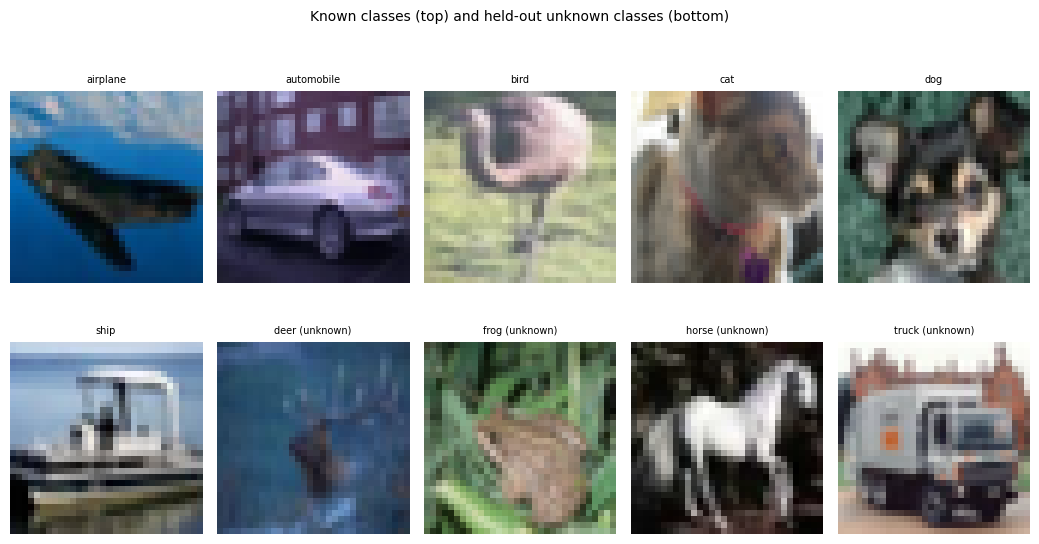

In [5]:
import torchvision
torchvision.datasets.CIFAR10.url = "https://data.brainchip.com/dataset-mirror/cifar10/cifar-10-python.tar.gz"
CIFAR_NAMES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
KNOWN   = ["airplane", "automobile", "bird", "cat", "dog", "ship"]
UNKNOWN = ["deer", "frog", "horse", "truck"]

def load_cifar():
    tr = torchvision.datasets.CIFAR10("data", train=True, download=True)
    te = torchvision.datasets.CIFAR10("data", train=False, download=True)
    return tr.data, np.array(tr.targets), te.data, np.array(te.targets)

def load_smoke():                                   # offline stand-in: 10 colour-coded noisy classes (only to test the code path)
    rng = np.random.default_rng(0); colors = rng.integers(40, 215, size=(10, 3))
    def make(n):
        y = np.repeat(np.arange(10), n)
        x = colors[y][:, None, None, :] + rng.normal(0, 45, size=(len(y), 32, 32, 3))
        return np.clip(x, 0, 255).astype(np.uint8), y
    (xa, ya), (xb, yb) = make(120), make(40)
    return xa, ya, xb, yb

Xtr_all, ytr_all, Xte_all, yte_all = load_cifar() if MODE == "cifar10" else load_smoke()
known_ids = [CIFAR_NAMES.index(c) for c in KNOWN]; unk_ids = [CIFAR_NAMES.index(c) for c in UNKNOWN]
remap = {old: new for new, old in enumerate(known_ids)}

def subset(x, y, ids):
    m = np.isin(y, ids); return x[m], y[m]

x_trv, y_trv = subset(Xtr_all, ytr_all, known_ids); y_trv = np.array([remap[v] for v in y_trv])
x_te_k, y_te_k = subset(Xte_all, yte_all, known_ids); y_te_k = np.array([remap[v] for v in y_te_k])
x_te_u, y_te_u_orig = subset(Xte_all, yte_all, unk_ids)                       # keep original ids for per-class analysis
rng = np.random.default_rng(SEED)
x_noise = np.clip(rng.normal(128, 64, size=(1000, 32, 32, 3)), 0, 255).astype(np.uint8)

perm = rng.permutation(len(x_trv)); n_val = int(0.10 * len(x_trv))
x_val, y_val = x_trv[perm[:n_val]], y_trv[perm[:n_val]]
x_tr,  y_tr  = x_trv[perm[n_val:]], y_trv[perm[n_val:]]
print(f"train {len(x_tr)} | val {len(x_val)} | unseen known test {len(x_te_k)} | unknown (held-out classes) test {len(x_te_u)} | noise {len(x_noise)}")
print("known:", KNOWN, "\nunknown:", UNKNOWN)
R["data"] = dict(train=len(x_tr), val=len(x_val), test_known=len(x_te_k), test_unknown=len(x_te_u), noise=len(x_noise), known=KNOWN, unknown=UNKNOWN)

def show_grid(imgs, titles, ncols, path, suptitle=""):
    n = len(imgs); nrows = max(1, math.ceil(n / ncols))
    fig, axs = plt.subplots(nrows, ncols, figsize=(2.1 * ncols, 3.0 * nrows)); axs = np.array(axs).reshape(-1)
    for a in axs: a.axis("off")
    for a, im, t in zip(axs, imgs, titles): a.imshow(im); a.set_title(t, fontsize=7)
    if suptitle: fig.suptitle(suptitle, fontsize=10)
    fig.tight_layout(); fig.savefig(path, dpi=130); plt.show(); plt.close(fig)

sel = [np.where(y_tr == c)[0][0] for c in range(len(KNOWN))] + [np.where(y_te_u_orig == u)[0][0] for u in unk_ids]
show_grid([x_tr[i] if k < len(KNOWN) else x_te_u[i] for k, i in enumerate(sel)],
          KNOWN + [f"{u} (unknown)" for u in UNKNOWN], 5, "outputs/00_samples.png", "Known classes (top) and held-out unknown classes (bottom)")

## 3 · Model and training

ResNet-18 (ImageNet weights) with the last layer replaced by `Dropout(0.3) → Linear(512, 6)`. The 512-number vector before the head is the **feature vector** used by the Mahalanobis score; the dropout lets us do MC-dropout later. All layers are fine-tuned with AdamW and cosine learning-rate decay. We deliberately use **plain cross-entropy (no label smoothing)** so that confidence scores are not artificially flattened.

In [6]:
MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)

def prep(xb_u8):                                    # uint8 [B,32,32,3] -> normalised float [B,3,RES,RES] on device
    x = torch.as_tensor(xb_u8).to(DEVICE).permute(0, 3, 1, 2).float() / 255
    if RES != 32: x = F.interpolate(x, size=(RES, RES), mode="bilinear", align_corners=False)
    return (x - MEAN) / STD

def augment(x):                                     # random horizontal flip + random shift
    flip = torch.rand(x.size(0), device=x.device) < 0.5
    x = torch.where(flip.view(-1, 1, 1, 1), x.flip(3), x)
    pad = RES // 8; x = F.pad(x, (pad,) * 4, mode="reflect")
    i, j = random.randint(0, 2 * pad), random.randint(0, 2 * pad)
    return x[:, :, i:i + RES, j:j + RES]

class Net(nn.Module):
    def __init__(self, n_classes, pretrained, p_drop=0.3):
        super().__init__()
        m = torchvision.models.resnet18(weights="IMAGENET1K_V1" if pretrained else None)
        self.backbone = nn.Sequential(*list(m.children())[:-1])          # conv layers + global average pool -> [B,512,1,1]
        self.head = nn.Sequential(nn.Dropout(p_drop), nn.Linear(512, n_classes))
    def forward(self, x):
        f = self.backbone(x).flatten(1)                                   # features [B,512]
        return self.head(f), f                                            # logits [B,6], features

@torch.no_grad()
def get_outputs(x_u8, bs=256):                      # -> logits [N,6], features [N,512] (numpy), model in eval mode
    model.eval(); L, Fe = [], []
    for i in range(0, len(x_u8), bs):
        lo, fe = model(prep(x_u8[i:i + bs])); L.append(lo.float().cpu()); Fe.append(fe.float().cpu())
    return torch.cat(L).numpy(), torch.cat(Fe).numpy()

model = Net(len(KNOWN), PRETRAINED).to(DEVICE)
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
steps_per_epoch = math.ceil(len(x_tr) / BATCH)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS * steps_per_epoch)
y_tr_t = torch.as_tensor(y_tr).long()

hist = []
t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    model.train(); order = np.random.permutation(len(x_tr)); run = 0.0
    for s in range(steps_per_epoch):
        idx = order[s * BATCH:(s + 1) * BATCH]
        xb = augment(prep(x_tr[idx])); yb = y_tr_t[idx].to(DEVICE)
        logits, _ = model(xb)
        assert logits.shape == (len(idx), len(KNOWN)) and yb.shape == (len(idx),)
        loss = F.cross_entropy(logits, yb)
        opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step(); run += loss.item()
    lv, _ = get_outputs(x_val)
    val_acc = float((lv.argmax(1) == y_val).mean()); val_loss = float(F.cross_entropy(torch.from_numpy(lv), torch.from_numpy(y_val).long()))
    hist.append(dict(epoch=epoch, train_loss=run / steps_per_epoch, val_loss=val_loss, val_acc=val_acc))
    print(f"epoch {epoch}/{EPOCHS} | train loss {run / steps_per_epoch:.4f} | val loss {val_loss:.4f} | val acc {val_acc:.4f} | {time.time() - t0:.0f}s")
R["training"] = hist

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 206MB/s]


epoch 1/5 | train loss 0.4685 | val loss 0.2912 | val acc 0.8927 | 13s
epoch 2/5 | train loss 0.2591 | val loss 0.2687 | val acc 0.9063 | 22s
epoch 3/5 | train loss 0.1836 | val loss 0.2141 | val acc 0.9230 | 32s
epoch 4/5 | train loss 0.1326 | val loss 0.2057 | val acc 0.9287 | 42s
epoch 5/5 | train loss 0.1035 | val loss 0.2026 | val acc 0.9283 | 52s


## 4 · Classification on unseen *known* images

accuracy on 6000 unseen known images: 0.9302
per-class recall: {'airplane': 0.948, 'automobile': 0.987, 'bird': 0.943, 'cat': 0.869, 'dog': 0.865, 'ship': 0.969}


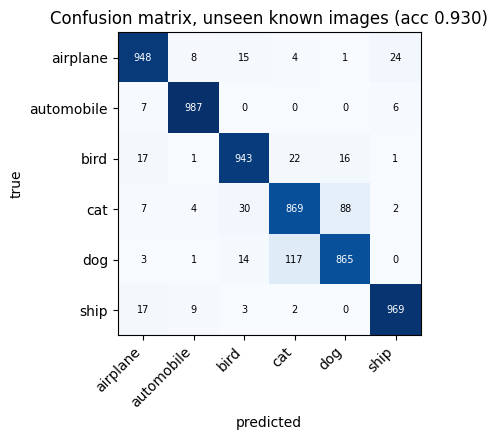

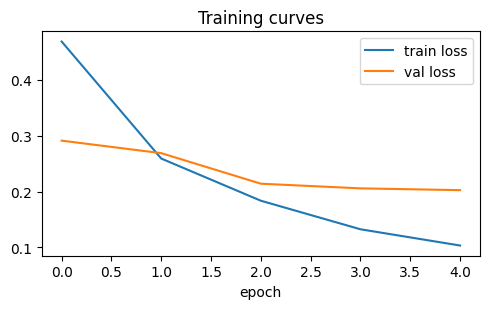

In [7]:
splits = {}
for name, x, y in [("train", x_tr, y_tr), ("val", x_val, y_val), ("known", x_te_k, y_te_k), ("unknown", x_te_u, None), ("noise", x_noise, None)]:
    lg, fe = get_outputs(x); splits[name] = dict(logits=lg, feats=fe, y=y)

def softmax_np(z):
    z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)

lg_k, y_k = splits["known"]["logits"], splits["known"]["y"]
pred_k = lg_k.argmax(1); acc = float((pred_k == y_k).mean())
cm = confusion_matrix(y_k, pred_k)
per_class = {KNOWN[c]: float(cm[c, c] / cm[c].sum()) for c in range(len(KNOWN))}
print(f"accuracy on {len(y_k)} unseen known images: {acc:.4f}")
print("per-class recall:", {k: round(v, 3) for k, v in per_class.items()})
R["classification"] = dict(accuracy=acc, per_class_recall=per_class, confusion=cm.tolist())

fig, ax = plt.subplots(figsize=(5, 4.5)); im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(KNOWN))); ax.set_xticklabels(KNOWN, rotation=45, ha="right"); ax.set_yticks(range(len(KNOWN))); ax.set_yticklabels(KNOWN)
for i in range(len(KNOWN)):
    for j in range(len(KNOWN)): ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"Confusion matrix, unseen known images (acc {acc:.3f})")
fig.tight_layout(); fig.savefig("outputs/01_confusion_matrix.png", dpi=130); plt.show(); plt.close(fig)

fig, ax = plt.subplots(figsize=(5, 3.2)); ax.plot([h["train_loss"] for h in hist], label="train loss"); ax.plot([h["val_loss"] for h in hist], label="val loss")
ax.set_xlabel("epoch"); ax.legend(); ax.set_title("Training curves"); fig.tight_layout(); fig.savefig("outputs/02_training_curves.png", dpi=130); plt.show(); plt.close(fig)

## 5 · Calibration: is the confidence honest?

A model is **calibrated** if, among predictions made with ~80 % confidence, ~80 % are correct. **ECE** (expected calibration error, 15 bins) is the average gap between confidence and accuracy. **Temperature scaling** divides the logits by one number *T* (fitted by minimising log-loss on the **validation** set, a one-parameter gradient fit) and does not change which class is predicted.

temperature T = 1.288
ECE  0.0204 -> 0.0075 | NLL 0.1986 -> 0.1914 | mean confidence 0.949 -> 0.930 (accuracy 0.930)


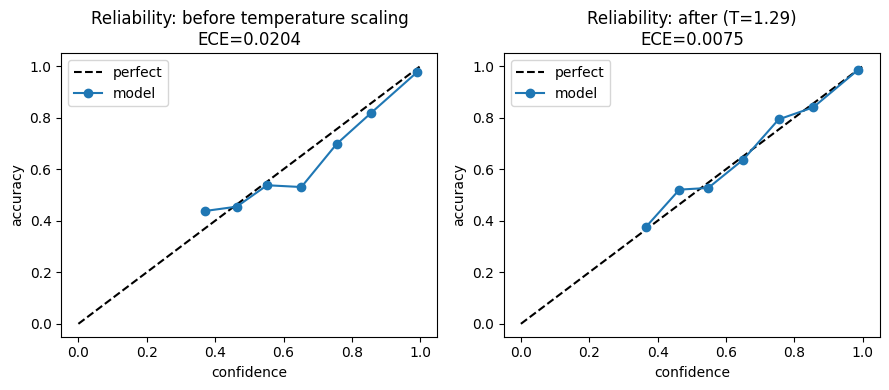

In [8]:
def ece_score(probs, y, n_bins=15):
    conf, pred = probs.max(1), probs.argmax(1); correct = (pred == y).astype(float); e = 0.0
    edges = np.linspace(0, 1, n_bins + 1)
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): e += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return float(e)

def nll_score(probs, y): return float(-np.log(probs[np.arange(len(y)), y] + 1e-12).mean())

def fit_temperature(logits, y):                     # minimise validation NLL over one scalar T = exp(logT)
    lg, yy = torch.from_numpy(logits).float(), torch.from_numpy(y).long()
    logT = torch.zeros(1, requires_grad=True); opt = torch.optim.LBFGS([logT], lr=0.1, max_iter=200)
    def closure():
        opt.zero_grad(); loss = F.cross_entropy(lg / logT.exp(), yy); loss.backward(); return loss
    opt.step(closure); return float(logT.exp().item())

T = fit_temperature(splits["val"]["logits"], splits["val"]["y"])
p_raw, p_ts = softmax_np(lg_k), softmax_np(lg_k / T)
cal = dict(T=T, ece_before=ece_score(p_raw, y_k), ece_after=ece_score(p_ts, y_k), nll_before=nll_score(p_raw, y_k), nll_after=nll_score(p_ts, y_k),
           mean_conf_before=float(p_raw.max(1).mean()), mean_conf_after=float(p_ts.max(1).mean()), accuracy=acc)
R["calibration"] = cal
print(f"temperature T = {T:.3f}")
print(f"ECE  {cal['ece_before']:.4f} -> {cal['ece_after']:.4f} | NLL {cal['nll_before']:.4f} -> {cal['nll_after']:.4f} | "
      f"mean confidence {cal['mean_conf_before']:.3f} -> {cal['mean_conf_after']:.3f} (accuracy {acc:.3f})")

fig, axs = plt.subplots(1, 2, figsize=(9, 4))
for ax, p, title in [(axs[0], p_raw, "before temperature scaling"), (axs[1], p_ts, f"after (T={T:.2f})")]:
    conf, correct = p.max(1), (p.argmax(1) == y_k).astype(float); edges = np.linspace(0, 1, 11)
    xs, ys = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() >= 5: xs.append(conf[m].mean()); ys.append(correct[m].mean())
    ax.plot([0, 1], [0, 1], "k--", label="perfect"); ax.plot(xs, ys, "o-", label="model")
    ax.set_xlabel("confidence"); ax.set_ylabel("accuracy"); ax.set_title(f"Reliability: {title}\nECE={ece_score(p, y_k):.4f}"); ax.legend()
fig.tight_layout(); fig.savefig("outputs/03_reliability.png", dpi=130); plt.show(); plt.close(fig)

## 6 · Uncertainty / unfamiliarity scores (7 methods)

Every method turns an image's model output into one number where **higher = more confident / more familiar**. An input is *rejected as unknown* when its score is below a threshold.

| Method | Score | Idea |
|---|---|---|
| MSP (baseline) | max softmax probability | confident ⇒ familiar |
| MSP + temperature scaling | max of softmax(logits / T) | same, with calibrated probabilities |
| Negative entropy | −entropy of softmax | flat distribution ⇒ unsure |
| Max logit | largest raw logit | keeps magnitude information that softmax discards |
| Energy | logsumexp(logits) | total "evidence" for any known class |
| Mahalanobis | −distance of the feature vector to the nearest class mean (shared covariance) | is the image *near* a known class in feature space? |
| MC dropout | −entropy of the average softmax over 20 dropout passes | disagreement between stochastic passes ⇒ unsure |

In [9]:
def logsumexp_np(z):
    m = z.max(1); return m + np.log(np.exp(z - m[:, None]).sum(1))
def entropy_np(p): return -(p * np.log(p + 1e-12)).sum(1)

class Mahalanobis:
    def fit(self, feats, y):
        self.mu = np.stack([feats[y == c].mean(0) for c in range(y.max() + 1)])
        centred = np.concatenate([feats[y == c] - self.mu[c] for c in range(y.max() + 1)])
        self.P = np.linalg.pinv(np.cov(centred, rowvar=False) + 1e-6 * np.eye(feats.shape[1]))     # shared precision matrix
        return self
    def score(self, feats):
        d = np.stack([np.einsum("ij,jk,ik->i", feats - m, self.P, feats - m) for m in self.mu], 1)
        return -d.min(1)

maha = Mahalanobis().fit(splits["train"]["feats"].astype(np.float64), splits["train"]["y"])

@torch.no_grad()
def mc_dropout_probs(feats, n=20):                  # dropout in the head stays ON; the backbone is deterministic
    torch.manual_seed(SEED); head = model.head; head.train(); f = torch.from_numpy(feats).float().to(DEVICE)
    out = np.stack([F.softmax(head(f), dim=1).cpu().numpy() for _ in range(n)]); head.eval(); return out

METHODS = {
    "MSP (baseline)":            lambda lg, fe: softmax_np(lg).max(1),
    "MSP + temp. scaling":       lambda lg, fe: softmax_np(lg / T).max(1),
    "Negative entropy":          lambda lg, fe: -entropy_np(softmax_np(lg)),
    "Max logit":                 lambda lg, fe: lg.max(1),
    "Energy":                    lambda lg, fe: logsumexp_np(lg),
    "Mahalanobis (features)":    lambda lg, fe: maha.score(fe.astype(np.float64)),
    "MC dropout (neg. entropy)": lambda lg, fe: -entropy_np(mc_dropout_probs(fe).mean(0)),
}
S = {m: {sp: fn(d["logits"], d["feats"]) for sp, d in splits.items()} for m, fn in METHODS.items()}   # scores cached per split
print("scores computed:", {m: {sp: v.shape[0] for sp, v in d.items()} for m, d in list(S.items())[:1]})

scores computed: {'MSP (baseline)': {'train': 27000, 'val': 3000, 'known': 6000, 'unknown': 4000, 'noise': 1000}}


## 7 · Detecting unfamiliar inputs

**Metrics** (unknown = positive class): **AUROC** (1.0 perfect, 0.5 coin flip), **AUPR-Out**, and **FPR@95TPR** (the fraction of unknown images wrongly accepted when 95 % of known test images are accepted). *Near-OOD* = the 4 held-out CIFAR classes; *far-OOD* = Gaussian noise.

NEAR-OOD: unseen known test images vs held-out classes (deer, frog, horse, truck)


,AUROC,AUPR_out,FPR95
MSP (baseline),0.787,0.672,0.793
MSP + temp. scaling,0.791,0.681,0.776
Negative entropy,0.794,0.698,0.725
Max logit,0.803,0.710,0.717
Energy,0.803,0.710,0.718
Mahalanobis (features),0.618,0.503,0.895
MC dropout (neg. entropy),0.795,0.699,0.723


FAR-OOD: unseen known test images vs Gaussian noise


,AUROC,AUPR_out,FPR95
MSP (baseline),0.989,0.905,0.020
MSP + temp. scaling,0.992,0.919,0.007
Negative entropy,0.995,0.918,0.000
Max logit,0.993,0.893,0.000
Energy,0.990,0.854,0.000
Mahalanobis (features),0.954,0.598,0.325
MC dropout (neg. entropy),0.995,0.918,0.000


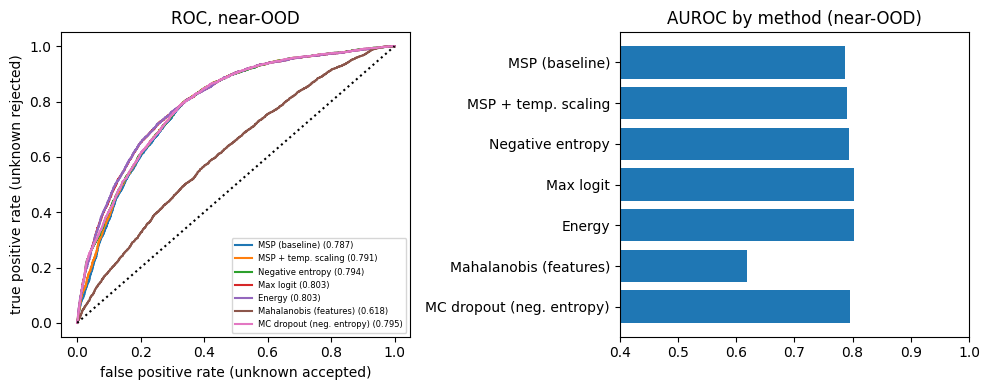

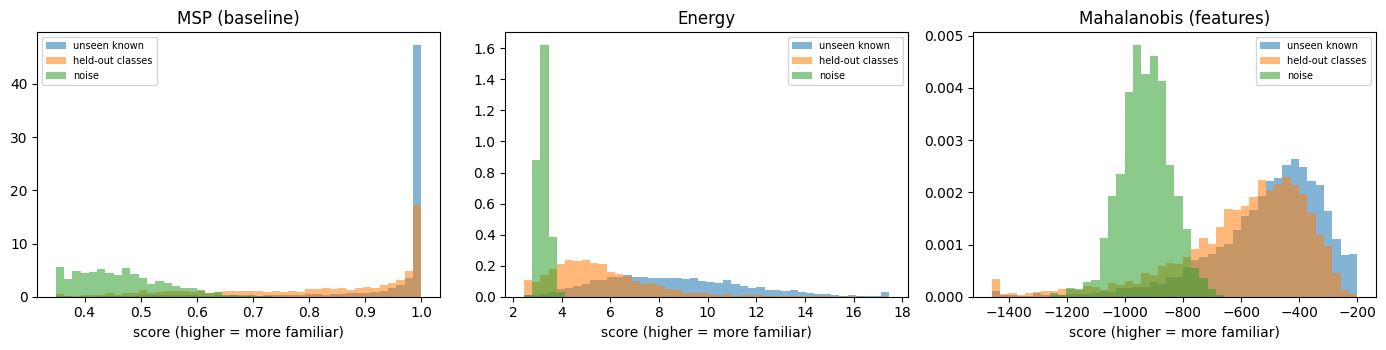

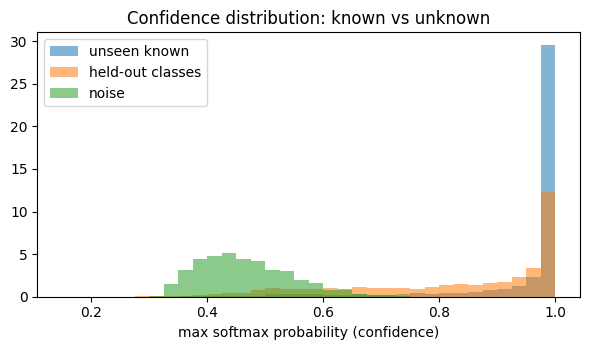

In [10]:
def ood_metrics(s_known, s_unknown):
    y = np.r_[np.zeros(len(s_known)), np.ones(len(s_unknown))]; s = np.r_[s_known, s_unknown]
    thr95 = np.percentile(s_known, 5)
    return dict(AUROC=float(roc_auc_score(y, -s)), AUPR_out=float(average_precision_score(y, -s)), FPR95=float((s_unknown >= thr95).mean()))

near = pd.DataFrame({m: ood_metrics(S[m]["known"], S[m]["unknown"]) for m in METHODS}).T
far  = pd.DataFrame({m: ood_metrics(S[m]["known"], S[m]["noise"]) for m in METHODS}).T
print("NEAR-OOD: unseen known test images vs held-out classes (deer, frog, horse, truck)"); display(near.round(3))
print("FAR-OOD: unseen known test images vs Gaussian noise"); display(far.round(3))
R["ood_near"], R["ood_far"] = near.to_dict("index"), far.to_dict("index")

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for m in METHODS:
    y = np.r_[np.zeros(len(S[m]["known"])), np.ones(len(S[m]["unknown"]))]; s = np.r_[S[m]["known"], S[m]["unknown"]]
    fpr, tpr, _ = roc_curve(y, -s); axs[0].plot(fpr, tpr, label=f"{m} ({near.loc[m, 'AUROC']:.3f})")
axs[0].plot([0, 1], [0, 1], "k:"); axs[0].set_xlabel("false positive rate (unknown accepted)"); axs[0].set_ylabel("true positive rate (unknown rejected)")
axs[0].set_title("ROC, near-OOD"); axs[0].legend(fontsize=6)
axs[1].barh(list(METHODS)[::-1], [near.loc[m, "AUROC"] for m in list(METHODS)[::-1]], label="near-OOD"); axs[1].set_xlim(0.4, 1.0)
axs[1].set_title("AUROC by method (near-OOD)"); fig.tight_layout(); fig.savefig("outputs/04_ood_roc.png", dpi=130); plt.show(); plt.close(fig)

# confidence distributions, known vs unknown vs noise
show = ["MSP (baseline)", "Energy", "Mahalanobis (features)"]
fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, m in zip(axs, show):
    allv = np.r_[S[m]["known"], S[m]["unknown"], S[m]["noise"]]; lo, hi = np.percentile(allv, [0.5, 99.5]); bins = np.linspace(lo, hi, 45)
    for sp, lab in [("known", "unseen known"), ("unknown", "held-out classes"), ("noise", "noise")]:
        ax.hist(np.clip(S[m][sp], lo, hi), bins=bins, alpha=0.55, density=True, label=lab)
    ax.set_title(m); ax.set_xlabel("score (higher = more familiar)"); ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig("outputs/05_score_distributions.png", dpi=130); plt.show(); plt.close(fig)

fig, ax = plt.subplots(figsize=(6, 3.6))
for sp, lab in [("known", "unseen known"), ("unknown", "held-out classes"), ("noise", "noise")]:
    ax.hist(softmax_np(splits[sp]["logits"]).max(1), bins=np.linspace(0.15, 1, 35), alpha=0.55, density=True, label=lab)
ax.set_xlabel("max softmax probability (confidence)"); ax.set_title("Confidence distribution: known vs unknown"); ax.legend(); fig.tight_layout()
fig.savefig("outputs/06_confidence_hist.png", dpi=130); plt.show(); plt.close(fig)

## 8 · Classification with vs without uncertainty handling

Rule: reject an input as "unknown" if its score is below the **5th percentile of the validation known images' scores** (so ~95 % of known images are kept). The threshold uses *only known validation data*, never the unknown test data.

*Without handling* the model must assign a known label to every input, so every unknown image is a wrong confident-looking answer by construction.

,known_kept,acc_on_kept,wrong_known_caught,unknown_rejected,noise_rejected
method,,,,,
No handling (always answer),1.000,0.930,0.000,0.000,0.000
MSP (baseline),0.948,0.953,0.360,0.216,0.982
MSP + temp. scaling,0.950,0.952,0.348,0.225,0.993
Negative entropy,0.945,0.953,0.370,0.287,1.000
Max logit,0.949,0.947,0.279,0.288,1.000
Energy,0.951,0.944,0.243,0.279,1.000
Mahalanobis (features),0.956,0.930,0.038,0.095,0.567
MC dropout (neg. entropy),0.944,0.953,0.368,0.292,1.000


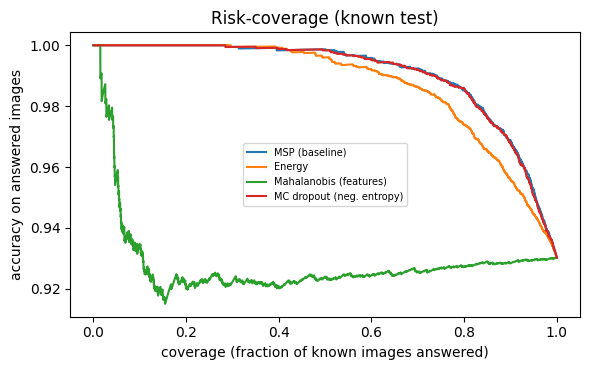

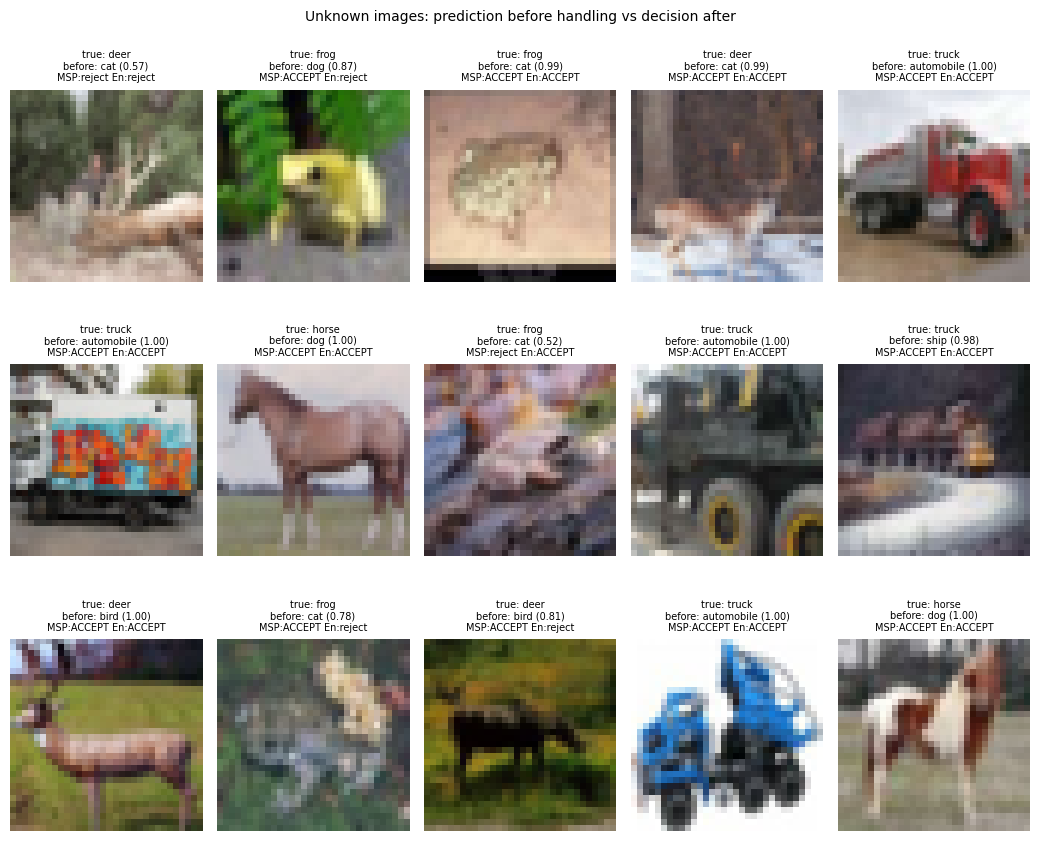

In [11]:
THR = {m: float(np.percentile(S[m]["val"], 5)) for m in METHODS}
wrong_k = pred_k != y_k
rows = [dict(method="No handling (always answer)", known_kept=1.0, acc_on_kept=acc, wrong_known_caught=0.0, unknown_rejected=0.0, noise_rejected=0.0)]
for m in METHODS:
    keep_k, keep_u, keep_n = S[m]["known"] >= THR[m], S[m]["unknown"] >= THR[m], S[m]["noise"] >= THR[m]
    rows.append(dict(method=m, known_kept=float(keep_k.mean()), acc_on_kept=float((pred_k[keep_k] == y_k[keep_k]).mean()),
                     wrong_known_caught=float((~keep_k[wrong_k]).mean()) if wrong_k.any() else float("nan"), unknown_rejected=float(1 - keep_u.mean()), noise_rejected=float(1 - keep_n.mean())))
handling = pd.DataFrame(rows).set_index("method"); display(handling.round(3))
R["handling"] = handling.to_dict("index"); R["thresholds_val_known_p5"] = THR

# risk-coverage: accuracy on the most-confident fraction of known images
fig, ax = plt.subplots(figsize=(6, 3.8))
for m in ["MSP (baseline)", "Energy", "Mahalanobis (features)", "MC dropout (neg. entropy)"]:
    order = np.argsort(-S[m]["known"]); corr = (pred_k[order] == y_k[order]).astype(float)
    cov = np.arange(1, len(corr) + 1) / len(corr); ax.plot(cov, np.cumsum(corr) / np.arange(1, len(corr) + 1), label=m)
ax.set_xlabel("coverage (fraction of known images answered)"); ax.set_ylabel("accuracy on answered images"); ax.set_title("Risk-coverage (known test)"); ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig("outputs/07_risk_coverage.png", dpi=130); plt.show(); plt.close(fig)

# before / after examples on unknown images
rng2 = np.random.default_rng(1); pick = rng2.choice(len(x_te_u), 15, replace=False)
pu = softmax_np(splits["unknown"]["logits"]); titles = []
for i in pick:
    msp_acc = S["MSP (baseline)"]["unknown"][i] >= THR["MSP (baseline)"]; en_acc = S["Energy"]["unknown"][i] >= THR["Energy"]
    titles.append(f"true: {CIFAR_NAMES[y_te_u_orig[i]]}\nbefore: {KNOWN[pu[i].argmax()]} ({pu[i].max():.2f})\nMSP:{'ACCEPT' if msp_acc else 'reject'} En:{'ACCEPT' if en_acc else 'reject'}")
show_grid([x_te_u[i] for i in pick], titles, 5, "outputs/08_before_after_examples.png", "Unknown images: prediction before handling vs decision after")

## 9 · Failure analysis

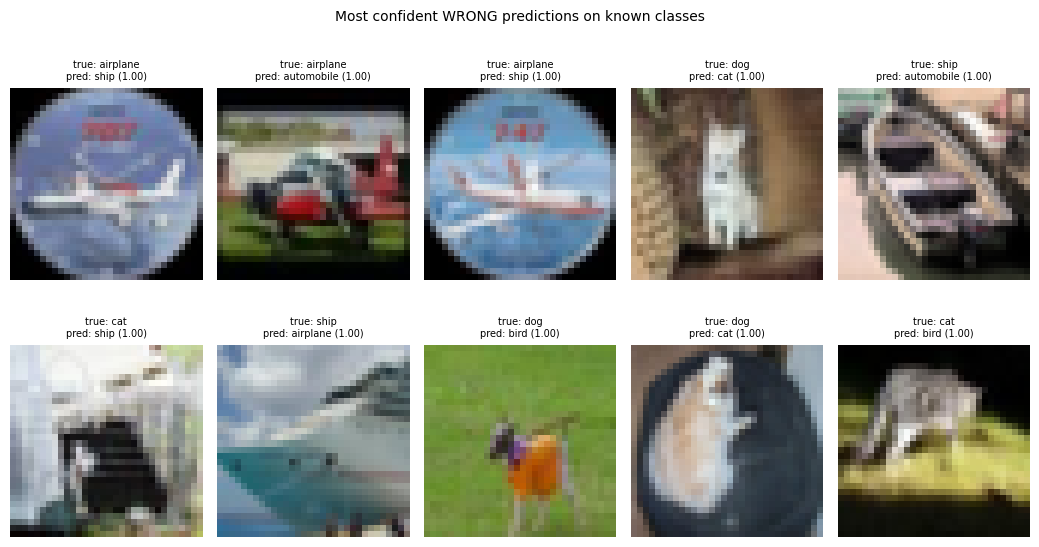

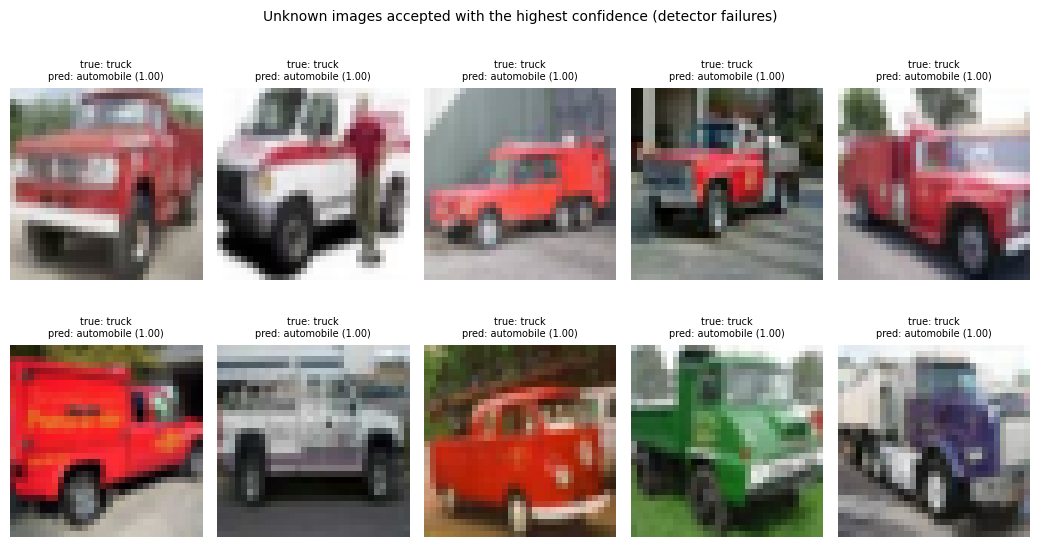

,n,accepted_MSP,accepted_Energy,accepted_Mahalanobis,mostly_called
unknown_class,,,,,
deer,1000,0.722,0.705,0.960,bird (40%)
frog,1000,0.771,0.697,0.957,cat (56%)
horse,1000,0.771,0.686,0.796,dog (65%)
truck,1000,0.871,0.795,0.906,automobile (79%)


,recall,rejected_MSP,rejected_Energy
known_class,,,
airplane,0.948,0.038,0.054
automobile,0.987,0.009,0.015
bird,0.943,0.053,0.031
cat,0.869,0.104,0.098
dog,0.865,0.087,0.050
ship,0.969,0.022,0.046


In [12]:
# (a) known images the model gets wrong with high confidence
msp_k = S["MSP (baseline)"]["known"]; wi = np.where(wrong_k)[0]; wi = wi[np.argsort(-msp_k[wi])][:10]
show_grid([x_te_k[i] for i in wi], [f"true: {KNOWN[y_k[i]]}\npred: {KNOWN[pred_k[i]]} ({msp_k[i]:.2f})" for i in wi], 5,
          "outputs/09_confident_errors.png", "Most confident WRONG predictions on known classes")

# (b) unknown images that slip through (accepted by MSP and Energy) with the highest confidence
msp_u = S["MSP (baseline)"]["unknown"]; ai = np.where(msp_u >= THR["MSP (baseline)"])[0]; ai = ai[np.argsort(-msp_u[ai])][:10]
show_grid([x_te_u[i] for i in ai], [f"true: {CIFAR_NAMES[y_te_u_orig[i]]}\npred: {KNOWN[pu[i].argmax()]} ({msp_u[i]:.2f})" for i in ai], 5,
          "outputs/10_missed_unknowns.png", "Unknown images accepted with the highest confidence (detector failures)")

# (c) per unknown class: how often is it accepted, and what does the model call it?
pred_u = pu.argmax(1); rows = []
for u in unk_ids:
    m = y_te_u_orig == u; most = np.bincount(pred_u[m], minlength=len(KNOWN)); r = dict(unknown_class=CIFAR_NAMES[u], n=int(m.sum()))
    for meth in ["MSP (baseline)", "Energy", "Mahalanobis (features)"]:
        r[f"accepted_{meth.split()[0]}"] = float((S[meth]["unknown"][m] >= THR[meth]).mean())
    r["mostly_called"] = f"{KNOWN[most.argmax()]} ({most.max() / m.sum():.0%})"; rows.append(r)
per_unk = pd.DataFrame(rows).set_index("unknown_class"); display(per_unk.round(3)); R["per_unknown_class"] = per_unk.to_dict("index")

# (d) which KNOWN classes are wrongly rejected by the detector?
rows = []
for c in range(len(KNOWN)):
    m = y_k == c; r = dict(known_class=KNOWN[c], recall=float((pred_k[m] == c).mean()))
    for meth in ["MSP (baseline)", "Energy"]: r[f"rejected_{meth.split()[0]}"] = float((S[meth]["known"][m] < THR[meth]).mean())
    rows.append(r)
rej = pd.DataFrame(rows).set_index("known_class"); display(rej.round(3)); R["known_rejection"] = rej.to_dict("index")

## 10 · Robustness to corrupted / low-quality images

Four corruptions at three severities are applied to **both** the known and the unknown test images. We report accuracy, calibration, how many clean-threshold **known** images are wrongly rejected, and OOD AUROC (known-corrupted vs unknown-corrupted).

,accuracy,ECE,ECE_temp_scaled,mean_conf,known_rejected_MSP,AUROC_MSP,known_rejected_Energy,AUROC_Energy,known_rejected_Mahalanobis,AUROC_Mahalanobis
condition,,,,,,,,,,
clean,0.930,0.020,0.008,0.949,0.052,0.787,0.049,0.803,0.044,0.618
gaussian_noise 0.05,0.839,0.064,0.030,0.902,0.110,0.738,0.145,0.727,0.042,0.582
gaussian_noise 0.1,0.579,0.206,0.151,0.784,0.280,0.625,0.372,0.605,0.063,0.553
gaussian_noise 0.2,0.310,0.328,0.265,0.638,0.592,0.521,0.741,0.525,0.214,0.530
blur 0.8,0.847,0.062,0.031,0.907,0.106,0.755,0.121,0.754,0.040,0.553
blur 1.5,0.520,0.278,0.222,0.798,0.262,0.584,0.384,0.537,0.047,0.506
blur 2.5,0.355,0.375,0.310,0.730,0.373,0.489,0.588,0.435,0.051,0.435
low_res 2,0.609,0.247,0.204,0.856,0.180,0.679,0.306,0.721,0.152,0.551
low_res 4,0.363,0.473,0.420,0.835,0.202,0.601,0.412,0.634,0.412,0.538


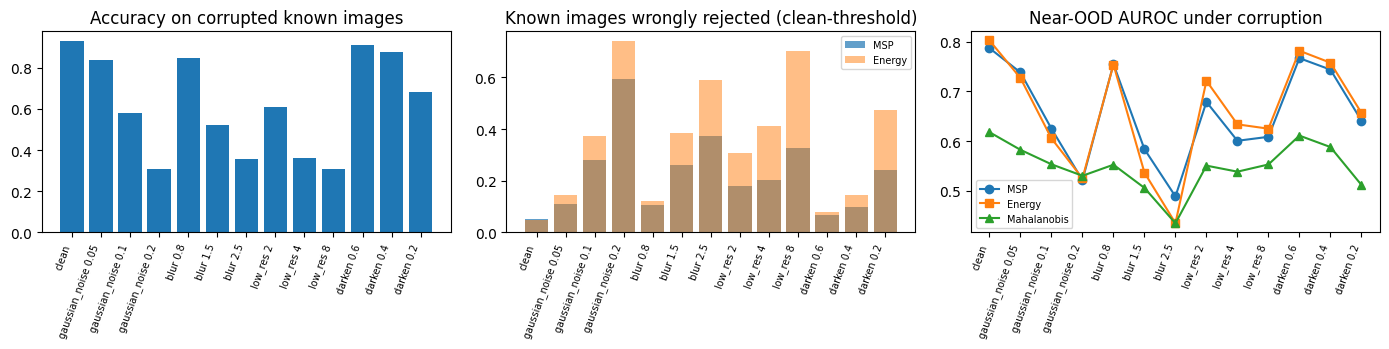

In [13]:
CORRUPTIONS = {"gaussian_noise": [0.05, 0.10, 0.20], "blur": [0.8, 1.5, 2.5], "low_res": [2, 4, 8], "darken": [0.6, 0.4, 0.2]}

def corrupt(x_u8, kind, level, seed=0):
    g = torch.Generator().manual_seed(seed); x = torch.as_tensor(x_u8).permute(0, 3, 1, 2).float() / 255
    if kind == "gaussian_noise": x = x + level * torch.randn(x.shape, generator=g)
    elif kind == "blur":         k = 2 * int(math.ceil(3 * level)) + 1; x = TF.gaussian_blur(x, [k, k], [level, level])
    elif kind == "low_res":      s = 32 // int(level); x = F.interpolate(F.interpolate(x, size=(s, s), mode="area"), size=(32, 32), mode="nearest")
    elif kind == "darken":       x = x * level
    return (x.clamp(0, 1) * 255).round().byte().permute(0, 2, 3, 1).numpy()

def eval_condition(xk, xu):
    lk, fk = get_outputs(xk); lu, fu = get_outputs(xu); out = {}
    pk = softmax_np(lk); out["accuracy"] = float((pk.argmax(1) == y_k).mean()); out["ECE"] = ece_score(pk, y_k); out["ECE_temp_scaled"] = ece_score(softmax_np(lk / T), y_k)
    out["mean_conf"] = float(pk.max(1).mean())
    for m in ["MSP (baseline)", "Energy", "Mahalanobis (features)"]:
        sk, su = METHODS[m](lk, fk), METHODS[m](lu, fu); short = m.split()[0]
        out[f"known_rejected_{short}"] = float((sk < THR[m]).mean()); out[f"AUROC_{short}"] = ood_metrics(sk, su)["AUROC"]
    return out

rows = [dict(condition="clean", **eval_condition(x_te_k, x_te_u))]
for kind, levels in CORRUPTIONS.items():
    for lv in levels: rows.append(dict(condition=f"{kind} {lv}", **eval_condition(corrupt(x_te_k, kind, lv), corrupt(x_te_u, kind, lv))))
robust = pd.DataFrame(rows).set_index("condition"); display(robust.round(3)); R["robustness"] = robust.to_dict("index")

fig, axs = plt.subplots(1, 3, figsize=(14, 3.6)); xs = np.arange(len(robust))
axs[0].bar(xs, robust["accuracy"]); axs[0].set_title("Accuracy on corrupted known images")
axs[1].bar(xs, robust["known_rejected_MSP"], alpha=0.7, label="MSP"); axs[1].bar(xs, robust["known_rejected_Energy"], alpha=0.5, label="Energy")
axs[1].set_title("Known images wrongly rejected (clean-threshold)"); axs[1].legend(fontsize=7)
axs[2].plot(xs, robust["AUROC_MSP"], "o-", label="MSP"); axs[2].plot(xs, robust["AUROC_Energy"], "s-", label="Energy"); axs[2].plot(xs, robust["AUROC_Mahalanobis"], "^-", label="Mahalanobis")
axs[2].set_title("Near-OOD AUROC under corruption"); axs[2].legend(fontsize=7)
for a in axs: a.set_xticks(xs); a.set_xticklabels(robust.index, rotation=70, ha="right", fontsize=7)
fig.tight_layout(); fig.savefig("outputs/11_robustness.png", dpi=130); plt.show(); plt.close(fig)

## 10B · Visual Explainability: Feature-Space t-SNE & Spatial Attribution (Grad-CAM)

To understand *why* the model accepts or rejects unfamiliar inputs, we inspect two internal representations:
1. **2D t-SNE Projection of the 512-D Penultimate Feature Space:** Visualizes how known classes form tight, separable clusters while held-out unknown classes (`deer`, `frog`, `horse`, `truck`) and `noise` fall into the interstitial regions between clusters (explaining why Mahalanobis distance works).
2. **Last-Layer Spatial Activation Heatmaps (Grad-CAM style):** Uses the $7 \times 7$ spatial feature map before global average pooling weighted by the predicted class's linear head weights to reveal which pixels drove the prediction on both known and unknown inputs.

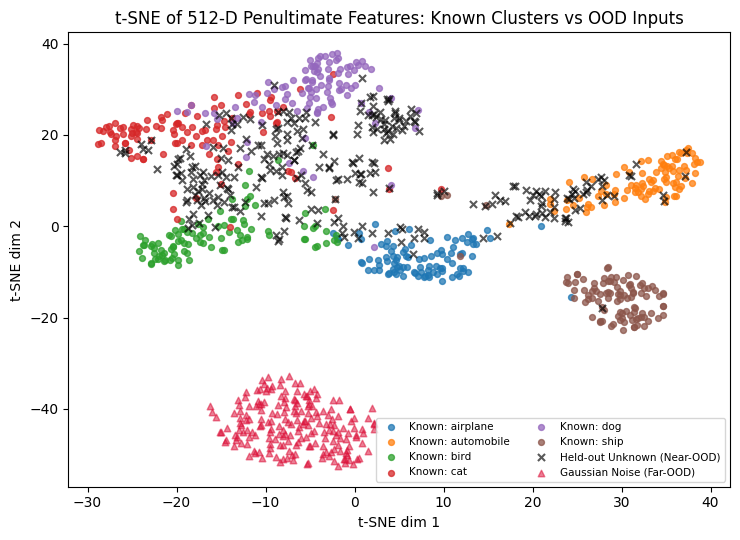

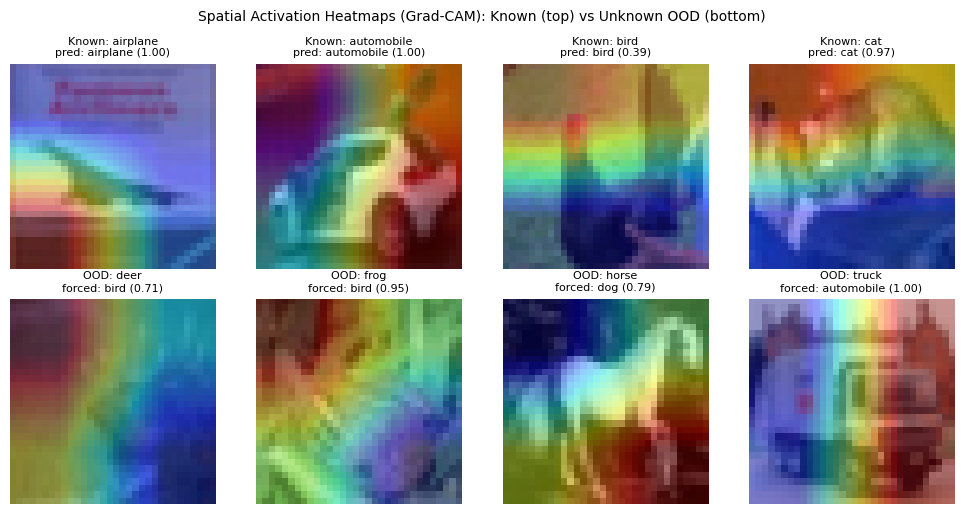

In [14]:
from sklearn.manifold import TSNE

# 1. t-SNE of 512-D feature vectors (Known vs Held-out Unknown vs Far-OOD Noise)
n_sub = 600 if MODE == "cifar10" else 120
rng_tsne = np.random.default_rng(SEED)
idx_k = rng_tsne.choice(len(splits["known"]["feats"]), min(n_sub, len(splits["known"]["feats"])), replace=False)
idx_u = rng_tsne.choice(len(splits["unknown"]["feats"]), min(n_sub // 2, len(splits["unknown"]["feats"])), replace=False)
idx_n = rng_tsne.choice(len(splits["noise"]["feats"]), min(n_sub // 3, len(splits["noise"]["feats"])), replace=False)

feats_all = np.concatenate([splits["known"]["feats"][idx_k], splits["unknown"]["feats"][idx_u], splits["noise"]["feats"][idx_n]], axis=0)
tsne = TSNE(n_components=2, perplexity=30, random_state=SEED, init="pca", learning_rate="auto")
emb = tsne.fit_transform(feats_all)

ek = emb[:len(idx_k)]
eu = emb[len(idx_k):len(idx_k)+len(idx_u)]
en = emb[len(idx_k)+len(idx_u):]
yk_sub = splits["known"]["y"][idx_k]

fig, ax = plt.subplots(figsize=(7.5, 5.5))
cmap = plt.get_cmap("tab10")
for c in range(len(KNOWN)):
    m = yk_sub == c
    ax.scatter(ek[m, 0], ek[m, 1], s=18, alpha=0.75, color=cmap(c), label=f"Known: {KNOWN[c]}")
ax.scatter(eu[:, 0], eu[:, 1], s=26, alpha=0.65, color="black", marker="x", label="Held-out Unknown (Near-OOD)")
ax.scatter(en[:, 0], en[:, 1], s=22, alpha=0.55, color="crimson", marker="^", label="Gaussian Noise (Far-OOD)")
ax.set_title("t-SNE of 512-D Penultimate Features: Known Clusters vs OOD Inputs")
ax.set_xlabel("t-SNE dim 1"); ax.set_ylabel("t-SNE dim 2")
ax.legend(fontsize=7.5, loc="best", ncol=2)
fig.tight_layout(); fig.savefig("outputs/12_tsne_features.png", dpi=130); plt.show(); plt.close(fig)

# 2. Spatial Activation Heatmaps (CAM / Grad-CAM on final conv block)
@torch.no_grad()
def compute_cam_grid(x_u8_batch):
    model.eval()
    x_norm = prep(x_u8_batch)
    # Extract spatial feature maps before Global Average Pool (backbone[:-1])
    conv_layers = nn.Sequential(*list(model.backbone.children())[:-1])
    fmap = conv_layers(x_norm)                              # [B, 512, H', W']
    logits, _ = model(x_norm)
    probs = F.softmax(logits, dim=1)
    preds = probs.argmax(dim=1)
    weights = model.head[1].weight[preds]                   # [B, 512]
    cam = torch.einsum("bchw,bc->bhw", fmap, weights)
    cam = F.relu(cam)
    cam_up = F.interpolate(cam.unsqueeze(1), size=(32, 32), mode="bilinear", align_corners=False).squeeze(1)
    cam_np = cam_up.cpu().numpy()
    cam_np = (cam_np - cam_np.min(axis=(1, 2), keepdims=True)) / (cam_np.max(axis=(1, 2), keepdims=True) - cam_np.min(axis=(1, 2), keepdims=True) + 1e-8)
    return cam_np, preds.cpu().numpy(), probs.max(dim=1).values.cpu().numpy()

sample_k_idx = [np.where(y_k == c)[0][0] for c in range(4)]
sample_u_idx = [np.where(y_te_u_orig == u)[0][0] for u in unk_ids[:4]]
batch_imgs = np.concatenate([x_te_k[sample_k_idx], x_te_u[sample_u_idx]], axis=0)
cams, cam_preds, cam_confs = compute_cam_grid(batch_imgs)

fig, axs = plt.subplots(2, 4, figsize=(10, 5.2))
for idx in range(8):
    r, c = idx // 4, idx % 4
    ax = axs[r, c]; ax.axis("off")
    ax.imshow(batch_imgs[idx])
    ax.imshow(cams[idx], cmap="jet", alpha=0.42)
    if idx < 4:
        true_lbl = KNOWN[y_k[sample_k_idx[idx]]]
        ax.set_title(f"Known: {true_lbl}\npred: {KNOWN[cam_preds[idx]]} ({cam_confs[idx]:.2f})", fontsize=8)
    else:
        true_lbl = CIFAR_NAMES[y_te_u_orig[sample_u_idx[idx - 4]]]
        ax.set_title(f"OOD: {true_lbl}\nforced: {KNOWN[cam_preds[idx]]} ({cam_confs[idx]:.2f})", fontsize=8)
fig.suptitle("Spatial Activation Heatmaps (Grad-CAM): Known (top) vs Unknown OOD (bottom)", fontsize=10)
fig.tight_layout(); fig.savefig("outputs/13_gradcam_heatmaps.png", dpi=130); plt.show(); plt.close(fig)

## 11 · Save artifacts and results

In [15]:
torch.save(model.state_dict(), "artifacts/model.pt")                    # large file: not committed to git (see .gitignore)
np.savez("artifacts/maha.npz", mu=maha.mu, P=maha.P)
json.dump(dict(classes=KNOWN, res=RES, T=T,
               thresholds={"msp": THR["MSP (baseline)"], "energy": THR["Energy"], "maha": THR["Mahalanobis (features)"], "entropy": THR["Negative entropy"]},
               mean=MEAN.flatten().tolist(), std=STD.flatten().tolist(), pretrained=PRETRAINED),
          open("artifacts/uq.json", "w"), indent=2)
json.dump(R, open("outputs/results.json", "w"), indent=2, default=float)
print("saved artifacts/model.pt, artifacts/maha.npz, artifacts/uq.json, outputs/results.json")

saved artifacts/model.pt, artifacts/maha.npz, artifacts/uq.json, outputs/results.json


## 12 · Generate README.md from the results of this run

In [16]:
def md_table(df, fmt="{:.3f}"):
    lines = ["| " + " | ".join([df.index.name or ""] + [str(c) for c in df.columns]) + " |", "|" + "---|" * (len(df.columns) + 1)]
    for i, row in df.iterrows():
        lines.append("| " + " | ".join([str(i)] + [fmt.format(v) if isinstance(v, (float, np.floating)) else str(v) for v in row]) + " |")
    return "\n".join(lines)

best_near, worst_near = near["AUROC"].idxmax(), near["AUROC"].idxmin()
best_far = far["AUROC"].idxmax()
facts = [
    f"Fine-tuned ResNet-18 reaches **{acc:.1%}** accuracy on {len(y_k)} unseen known images; weakest class: **{min(per_class, key=per_class.get)}** ({min(per_class.values()):.1%} recall).",
    f"Calibration: ECE {cal['ece_before']:.3f} → {cal['ece_after']:.3f} after temperature scaling (T = {T:.2f}); mean confidence {cal['mean_conf_before']:.3f} → {cal['mean_conf_after']:.3f} vs accuracy {acc:.3f}.",
    f"Near-OOD (held-out classes): best method **{best_near}** (AUROC {near.loc[best_near, 'AUROC']:.3f}); worst **{worst_near}** (AUROC {near.loc[worst_near, 'AUROC']:.3f}); baseline MSP {near.loc['MSP (baseline)', 'AUROC']:.3f}.",
    f"Far-OOD (noise): best method **{best_far}** (AUROC {far.loc[best_far, 'AUROC']:.3f}).",
    f"Without handling, 100 % of the {len(x_te_u)} unknown images receive a known label. With MSP rejection {handling.loc['MSP (baseline)', 'unknown_rejected']:.1%} are rejected, with Energy {handling.loc['Energy', 'unknown_rejected']:.1%}, with Mahalanobis {handling.loc['Mahalanobis (features)', 'unknown_rejected']:.1%} (while keeping ~{handling.loc['MSP (baseline)', 'known_kept']:.0%} of known images).",
    f"Hardest held-out class for the MSP detector: **{per_unk['accepted_MSP'].idxmax()}** ({per_unk['accepted_MSP'].max():.1%} accepted, mostly called {per_unk.loc[per_unk['accepted_MSP'].idxmax(), 'mostly_called']}).",
    f"Under the worst tested corruption for accuracy (**{robust['accuracy'].idxmin()}**) accuracy falls to {robust['accuracy'].min():.1%} and the MSP detector rejects {robust.loc[robust['accuracy'].idxmin(), 'known_rejected_MSP']:.1%} of known images.",
]
README = f'''# The Model That Doesn't Know: Open-Set Image Classification & Uncertainty Estimation

An image classification and Out-of-Distribution (OOD) detection system built around an ImageNet-pretrained **ResNet-18** fine-tuned on **6 known categories** (`airplane`, `automobile`, `bird`, `cat`, `dog`, `ship`), equipped with **7 uncertainty estimation methods**, **post-hoc temperature calibration**, **corruption robustness stress-testing**, and **visual explainability (t-SNE + Grad-CAM)**.

---

## 1. Problem Formulation & Architecture

Standard neural classifiers trained with Cross-Entropy loss apply a Softmax layer over $K$ known logits:

$$P(y = i \\mid x) = \\frac{{e^{{z_i}}}}{{\\sum_{{j=1}}^{{K}} e^{{z_j}}}}$$

Because Softmax normalizes probabilities to sum to $1.0$ and exponentiates raw logits, unfamiliar inputs from unseen categories are frequently assigned high confidence toward whichever known class shares superficial visual textures. To solve this, our pipeline decouples **feature extraction ($f_\\theta(x) \\in \\mathbb{{R}}^{{512}}$)** and **classification ($g_\\phi(f) \\in \\mathbb{{R}}^6$)** from an **Uncertainty Gatekeeper $S(x)$** tuned strictly on validation in-distribution data.

![Dataset Samples](outputs/00_samples.png)

### Dataset & Preprocessing Pipeline
* **Dataset:** CIFAR-10 (`torchvision`), partitioned into **In-Distribution (ID)** and **Out-of-Distribution (OOD)** splits.
* **Known Categories (6):** `{', '.join(KNOWN)}`.
* **Near-OOD Unknown Categories (4):** `{', '.join(UNKNOWN)}` — deliberately held out from training and validation to test semantic similarity confusion (`truck` vs `automobile`, `deer`/`horse` vs `cat`/`dog`).
* **Far-OOD Set:** `1,000` synthetic Gaussian noise images.
* **Split Sizes:** Train: `{len(x_tr)}` | Validation (ID only, for Temperature $T$ & 5th-percentile threshold $\\tau$): `{len(x_val)}` | Unseen Known Test: `{len(x_te_k)}` | Unknown Test: `{len(x_te_u)}`.
* **Preprocessing:** Cast to `[0, 1]`, bilinear upsampling `32×32 → {RES}×{RES}` to match pretrained ResNet receptive fields, ImageNet channel normalization (`mean=[0.485, 0.456, 0.406]`, `std=[0.229, 0.224, 0.225]`), plus random horizontal flips and reflection-padded crops during training.

---

## 2. Classification & Confidence Calibration on Unseen Known Images

* **Unseen Known Test Accuracy:** **{acc:.2%}** across `{len(y_k)}` test images.
* **Confidence Calibration:** Post-hoc Temperature Scaling ($z_i / T$) fitted via L-BFGS on validation Negative Log-Likelihood (NLL) found optimal temperature **$T = {T:.3f}$**, reducing Expected Calibration Error (ECE, 15 bins) from **{cal['ece_before']:.4f} → {cal['ece_after']:.4f}** and NLL from **{cal['nll_before']:.4f} → {cal['nll_after']:.4f}** without altering top-1 accuracy.

| Confusion Matrix | Training Curves |
| :---: | :---: |
| ![Confusion Matrix](outputs/01_confusion_matrix.png) | ![Training Curves](outputs/02_training_curves.png) |

![Reliability Diagram](outputs/03_reliability.png)

---

## 3. Uncertainty & Out-of-Distribution (OOD) Detection Benchmark (7 Methods)

We compare 7 scoring functions (oriented so higher score = higher familiarity/confidence):
1. **MSP (Baseline):** $\\max_i P(y=i \\mid x)$
2. **MSP + Temperature Scaling:** $\\max_i \\text{{Softmax}}(z / T)_i$
3. **Negative Shannon Entropy:** $\\sum_i P(y=i \\mid x) \\log P(y=i \\mid x)$
4. **Max Logit:** $\\max_i z_i$ (preserves pre-softmax magnitude)
5. **Energy Score:** $\\log \\sum_i e^{{z_i}}$ (helmholtz free energy of logits)
6. **Mahalanobis Distance:** $-\\min_c (f - \\mu_c)^\\top \\Sigma^{{-1}} (f - \\mu_c)$ in 512-D feature space
7. **Monte Carlo (MC) Dropout:** Negative entropy of mean softmax across 20 stochastic forward passes ($p=0.3$)

### Near-OOD Detection (`deer`, `frog`, `horse`, `truck` vs Known Test)

{md_table(near)}

### Far-OOD Detection (Gaussian Noise vs Known Test)

{md_table(far)}

![OOD ROC Curves](outputs/04_ood_roc.png)
![Score Distributions](outputs/05_score_distributions.png)
![Confidence Histogram](outputs/06_confidence_hist.png)

---

## 4. Classification Behavior: Before vs. After Uncertainty Handling

Using the **5th percentile of validation known scores** as the rejection threshold $\\tau$ (targeting ~95% TPR on known inputs without peeking at OOD data):

{md_table(handling)}

![Risk Coverage Curve](outputs/07_risk_coverage.png)
![Before vs After Examples](outputs/08_before_after_examples.png)

---

## 5. Failure Analysis & Visual Explainability (t-SNE & Grad-CAM)

### Per-Unknown-Class Breakdown (Which OOD Classes Fool the Gatekeeper?)

{md_table(per_unk)}

### False Rejections by Known Class

{md_table(rej)}

| High-Confidence Known Errors | Missed Unknowns (Accepted OOD Inputs) |
| :---: | :---: |
| ![Confident Errors](outputs/09_confident_errors.png) | ![Missed Unknowns](outputs/10_missed_unknowns.png) |

| 512-D Feature Space t-SNE | Spatial Activation Heatmaps (Grad-CAM) |
| :---: | :---: |
| ![t-SNE Features](outputs/12_tsne_features.png) | ![Grad-CAM Heatmaps](outputs/13_gradcam_heatmaps.png) |

---

## 6. Robustness Against Image Corruptions

We evaluate model accuracy, calibration, false-rejection rate, and OOD AUROC across 4 corruption types (`gaussian_noise`, `blur`, `low_res`, `darken`) at 3 severity levels each:

{md_table(robust)}

![Corruption Robustness](outputs/11_robustness.png)

---

## 7. Key Empirical Observations
''' + "\n".join(f"* {f}" for f in facts) + f'''

---

## 8. Limitations
* **Near-OOD Semantic Overlap at Low Resolution:** Native CIFAR-10 images are $32 \\times 32$ upsampled to ${RES} \\times {RES}$. Fine-grained features separating `truck` from `automobile` or `deer`/`horse` from `dog`/`cat` are blurred, bounding post-hoc OOD AUROC.
* **Static Threshold Shift Under Covariate Shift:** Thresholds $\\tau$ calibrated on clean validation data reject a higher proportion of valid known inputs when images suffer severe blur or noise (aleatoric uncertainty).
* **Gaussian Assumption in Mahalanobis:** Class-conditional feature distributions in ResNet-18 are not strictly multivariate Gaussian with identical covariance across classes.

---

## 9. How to Reproduce & Run the Real-Time Gradio Demo
```bash
pip install -r requirements.txt
# 1. Run uncertainty_classifier.ipynb on Colab (GPU) or via nbconvert:
jupyter nbconvert --to notebook --execute --inplace uncertainty_classifier.ipynb
# 2. Launch the interactive Gradio web app (with Grad-CAM heatmap & multi-detector diagnostics):
python app.py
```
'''
open("README.md", "w").write(README)
shutil.make_archive("uq_results", "zip", ".", "outputs")
print("README.md written;", len(README), "characters")
try:
    from google.colab import files
    files.download("README.md"); files.download("uq_results.zip"); files.download("artifacts/uq.json")
except Exception:
    pass

README.md written; 10526 characters


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>